<a href="https://colab.research.google.com/github/jahidhasan-cse/mental-health-score-predictor/blob/main/Mental_Health_Score_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [60]:
# Import required libraries

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')


In [61]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("shivasingh4945/student-social-media-and-mental-health-impact")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'student-social-media-and-mental-health-impact' dataset.
Path to dataset files: /kaggle/input/student-social-media-and-mental-health-impact


## 1. Load and Explore the Dataset


In [62]:
# Display the files available in the downloaded dataset
import os

os.listdir(path)

['Student Social Media And Mental Health Impact.csv']

In [63]:
# Load the dataset
df = pd.read_csv(f"{path}/Student Social Media And Mental Health Impact.csv")

df.head()

,Age,Gender,Country,Academic_Level,Most_Used_Platform,Purpose_Of_Use,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Stress_Level,Mental_Health_Score
0,21,Male,Other,Undergraduate,Facebook,Networking,4.0,134,4.5,2.2,6.7,Medium,6.8
1,23,Female,Other,Graduate,LinkedIn,Education,1.6,73,7.0,2.4,8.6,Low,7.6
2,22,Male,Canada,Undergraduate,Instagram,Entertainment,4.6,166,4.0,1.8,6.7,Medium,7.0
3,18,Male,Other,High School,Snapchat,Entertainment,7.0,220,1.0,1.7,5.4,Very High,5.3
4,24,Female,Other,Graduate,Facebook,Networking,7.5,237,1.0,1.1,5.0,Very High,4.4


In [64]:
df.shape

(5000, 13)

In [65]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Age                      5000 non-null   int64  
 1   Gender                   5000 non-null   object 
 2   Country                  5000 non-null   object 
 3   Academic_Level           5000 non-null   object 
 4   Most_Used_Platform       5000 non-null   object 
 5   Purpose_Of_Use           5000 non-null   object 
 6   Avg_Daily_Usage_Hours    5000 non-null   float64
 7   Daily_Unlocks            5000 non-null   int64  
 8   Study_Hours              5000 non-null   float64
 9   Physical_Activity_Hours  5000 non-null   float64
 10  Sleep_Hours_Per_Night    5000 non-null   float64
 11  Stress_Level             5000 non-null   object 
 12  Mental_Health_Score      5000 non-null   float64
dtypes: float64(5), int64(2), object(6)
memory usage: 507.9+ KB


In [66]:
df.columns

Index(['Age', 'Gender', 'Country', 'Academic_Level', 'Most_Used_Platform',
       'Purpose_Of_Use', 'Avg_Daily_Usage_Hours', 'Daily_Unlocks',
       'Study_Hours', 'Physical_Activity_Hours', 'Sleep_Hours_Per_Night',
       'Stress_Level', 'Mental_Health_Score'],
      dtype='object')

In [67]:
df.describe()

,Age,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Mental_Health_Score
count,5000.00000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,20.82180,5.078460,171.452600,3.008420,1.751000,6.634580,6.230980
std,1.73662,1.653913,42.858254,1.637018,0.668398,1.221391,1.278701
min,18.00000,1.000000,62.000000,0.300000,-0.400000,3.600000,3.600000
25%,19.00000,3.800000,140.000000,1.500000,1.300000,5.600000,5.100000
50%,21.00000,5.000000,171.000000,2.800000,1.700000,6.600000,6.100000
75%,22.00000,6.300000,204.000000,4.200000,2.200000,7.500000,7.100000
max,24.00000,8.800000,273.000000,8.300000,4.100000,9.900000,9.400000


In [68]:
df.describe(include='object')

,Gender,Country,Academic_Level,Most_Used_Platform,Purpose_Of_Use,Stress_Level
count,5000,5000,5000,5000,5000,5000
unique,2,111,3,12,4,4
top,Male,Other,Undergraduate,Instagram,Entertainment,Very High
freq,2635,1880,3632,1130,2552,1621


In [69]:
df.duplicated().sum()

np.int64(2)

In [70]:
df[df.duplicated()]

,Age,Gender,Country,Academic_Level,Most_Used_Platform,Purpose_Of_Use,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Stress_Level,Mental_Health_Score
2405,19,Female,Other,Undergraduate,LinkedIn,Education,6.1,202,1.0,2.1,5.8,High,4.1
2463,21,Male,USA,Undergraduate,Snapchat,Entertainment,3.9,126,5.1,2.6,7.1,Low,7.5


In [71]:
df.drop_duplicates(inplace=True)

In [72]:
df.duplicated().sum()

np.int64(0)

## Exploratory Data Analysis (EDA)


In [73]:
df.columns

Index(['Age', 'Gender', 'Country', 'Academic_Level', 'Most_Used_Platform',
       'Purpose_Of_Use', 'Avg_Daily_Usage_Hours', 'Daily_Unlocks',
       'Study_Hours', 'Physical_Activity_Hours', 'Sleep_Hours_Per_Night',
       'Stress_Level', 'Mental_Health_Score'],
      dtype='object')

In [74]:
# Analyze the target variable
df['Mental_Health_Score'].describe()

,Mental_Health_Score
count,4998.000000
mean,6.231152
std,1.278476
min,3.600000
25%,5.100000
50%,6.100000
75%,7.100000
max,9.400000


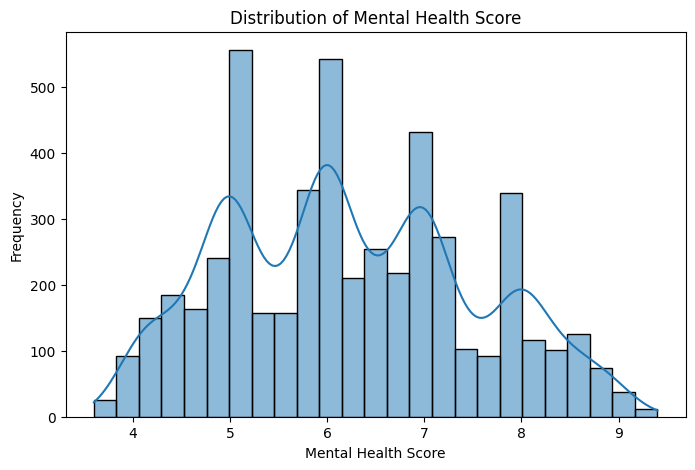

In [75]:
# Visualize the distribution of the target variable
plt.figure(figsize=(8, 5))

sns.histplot(df['Mental_Health_Score'], kde=True)

plt.title('Distribution of Mental Health Score')
plt.xlabel('Mental Health Score')
plt.ylabel('Frequency')
plt.show()

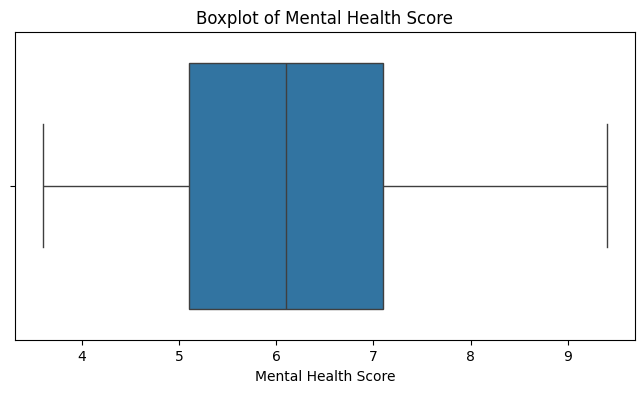

In [76]:
# Check the target variable for potential outliers
plt.figure(figsize=(8, 4))

sns.boxplot(x=df['Mental_Health_Score'])

plt.title('Boxplot of Mental Health Score')
plt.xlabel('Mental Health Score')
plt.show()

In [77]:
# Identify all numerical features
numerical_features = df.select_dtypes(include=np.number).columns

numerical_features

Index(['Age', 'Avg_Daily_Usage_Hours', 'Daily_Unlocks', 'Study_Hours',
       'Physical_Activity_Hours', 'Sleep_Hours_Per_Night',
       'Mental_Health_Score'],
      dtype='object')

In [78]:
target_correlation = (
    df[numerical_features]
    .corr()['Mental_Health_Score']
    .sort_values(ascending=False)
)

target_correlation

,Mental_Health_Score
Mental_Health_Score,1.000000
Sleep_Hours_Per_Night,0.766462
Study_Hours,0.752483
Physical_Activity_Hours,0.521591
Age,0.100464
Daily_Unlocks,-0.790830
Avg_Daily_Usage_Hours,-0.816485


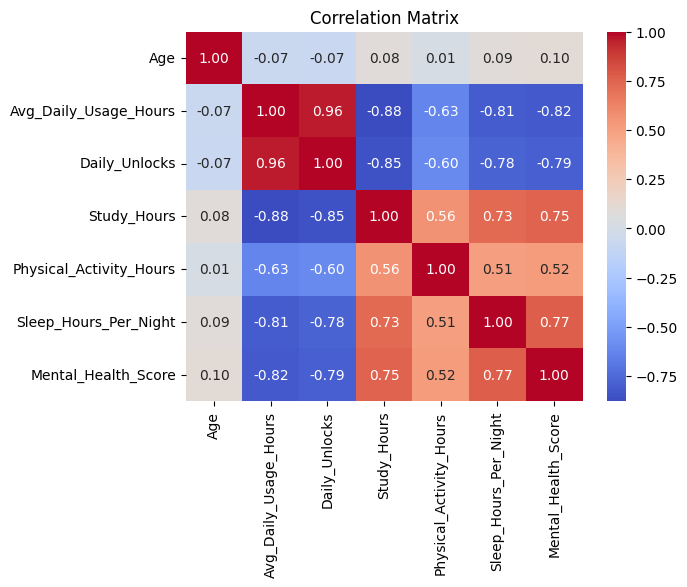

In [79]:
# Correlation Heatmap
# Plot the correlation matrix

sns.heatmap(
    df[numerical_features].corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Matrix')
plt.show()

In [80]:
df['Stress_Level'].unique()

array(['Medium', 'Low', 'Very High', 'High'], dtype=object)

In [81]:
order = ['Low','Medium','High','Very High' ]

<Axes: xlabel='Stress_Level', ylabel='Mental_Health_Score'>

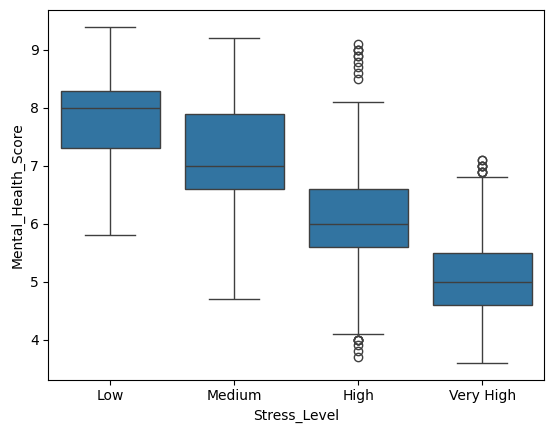

In [82]:
sns.boxplot(x='Stress_Level', y='Mental_Health_Score', data=df, order=order)

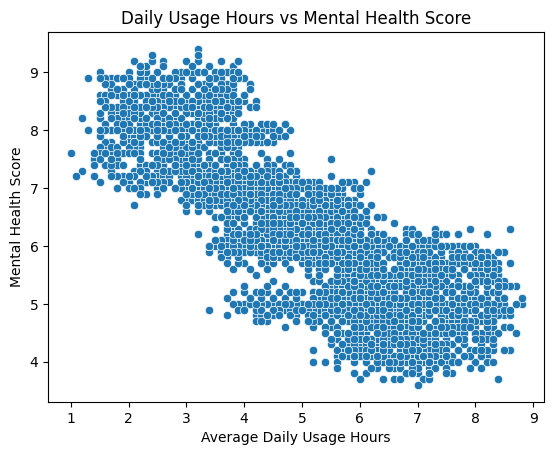

In [83]:
# Daily Usage Hours vs Mental Health Score

sns.scatterplot(x='Avg_Daily_Usage_Hours', y='Mental_Health_Score',data=df)
plt.title('Daily Usage Hours vs Mental Health Score')
plt.xlabel('Average Daily Usage Hours')
plt.ylabel('Mental Health Score')
plt.show()

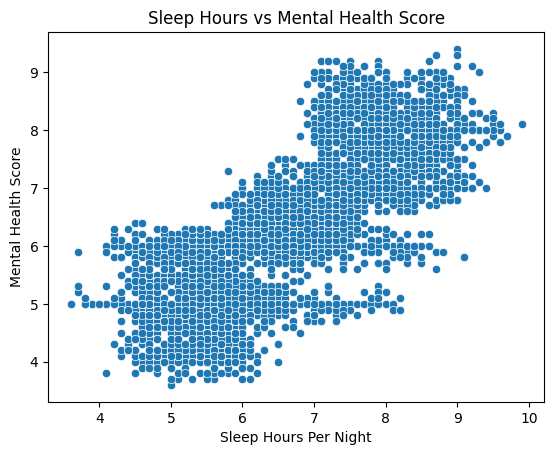

In [84]:
sns.scatterplot(data=df, x='Sleep_Hours_Per_Night', y='Mental_Health_Score')
plt.title('Sleep Hours vs Mental Health Score')
plt.xlabel('Sleep Hours Per Night')
plt.ylabel('Mental Health Score')
plt.show()

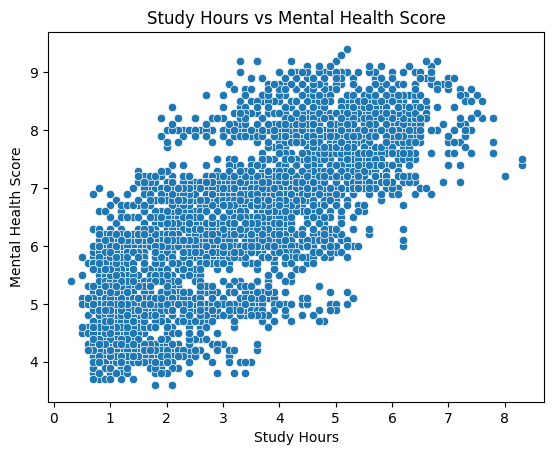

In [85]:
sns.scatterplot (data= df, x='Study_Hours', y = 'Mental_Health_Score')
plt.title('Study Hours vs Mental Health Score')
plt.xlabel('Study Hours')
plt.ylabel('Mental Health Score')
plt.show()

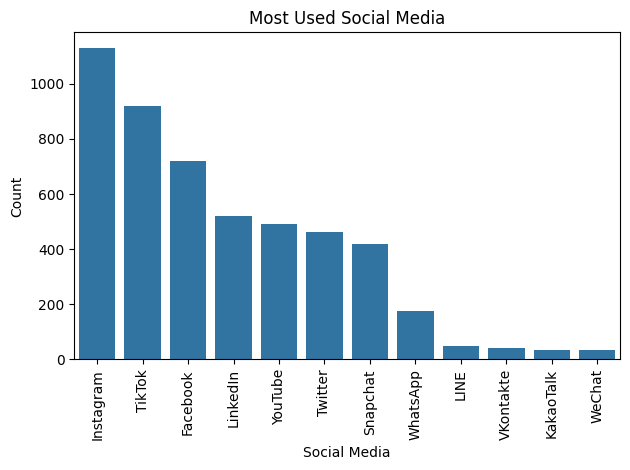

In [86]:
sns.countplot(data = df,
              x = 'Most_Used_Platform',
              order = df['Most_Used_Platform'].value_counts().index)
plt.title('Most Used Social Media')
plt.xlabel('Social Media')
plt.ylabel('Count')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [87]:
df['Most_Used_Platform'].value_counts()

,count
Most_Used_Platform,
Instagram,1130
TikTok,918
Facebook,719
LinkedIn,522
YouTube,491
Twitter,462
Snapchat,419
WhatsApp,175
LINE,50


## Checking Outliers

In [90]:
df[numerical_features].head()

,Age,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Mental_Health_Score
0,21,4.0,134,4.5,2.2,6.7,6.8
1,23,1.6,73,7.0,2.4,8.6,7.6
2,22,4.6,166,4.0,1.8,6.7,7.0
3,18,7.0,220,1.0,1.7,5.4,5.3
4,24,7.5,237,1.0,1.1,5.0,4.4


In [98]:
Q1 = df[numerical_features].quantile(0.25)
Q3 = df[numerical_features].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = ((df[numerical_features] < lower_bound) | (df[numerical_features] > upper_bound))
outliers.sum()

,0
Age,0
Avg_Daily_Usage_Hours,0
Daily_Unlocks,0
Study_Hours,2
Physical_Activity_Hours,22
Sleep_Hours_Per_Night,0
Mental_Health_Score,0


## Data Cleaning

In [101]:
# Coverting Neagtive or Unreal Value to realstic Value
df['Physical_Activity_Hours'] = (
    df['Physical_Activity_Hours'].clip(lower=0)
)

## Skewness

Skewness shows the **asymmetry of a data distribution** and indicates the relationship between **Mean, Median, and Mode**.

- **Symmetric:** Mean ≈ Median ≈ Mode → Skewness ≈ 0
- **Right-skewed (+):** Mean > Median > Mode
- **Left-skewed (-):** Mean < Median < Mode

A higher absolute skewness indicates a more asymmetric distribution.

In [103]:
df[numerical_features].skew()

,0
Age,0.155008
Avg_Daily_Usage_Hours,0.005575
Daily_Unlocks,0.002309
Study_Hours,0.436125
Physical_Activity_Hours,0.053288
Sleep_Hours_Per_Night,0.123919
Mental_Health_Score,0.207086


## Feature Engineering: Grouping `Country`

- `Country` has **111 unique values**, so direct one-hot encoding would create **110+ columns** and may cause a high-dimensional feature space.
- Dropping `Country` completely would also remove potentially useful information.
- **Solution:** Keep the **Top 10 most frequent countries** as separate categories and group all remaining countries into **`Other`**.
- This reduces **high cardinality** while preserving the most useful country-level information.

In [116]:
top_countries = df['Country'].value_counts().head(11).index.tolist()
top_countries

['Other',
 'India',
 'USA',
 'Canada',
 'Australia',
 'UK',
 'Germany',
 'Mexico',
 'Turkey',
 'France',
 'Spain']

In [118]:
def group_countries(country):
    if country in top_countries:
        return country
    else:
        return 'Other'


In [120]:
# Create a new column by grouping less frequent countries into 'Other'
df['Grouped_Country'] = df['Country'].apply(group_countries)

In [121]:
df['Grouped_Country'].value_counts()

,count
Grouped_Country,
Other,3148
India,389
USA,354
Canada,230
Australia,198
UK,185
Germany,136
Turkey,94
Mexico,94


In [130]:
from sklearn.model_selection import train_test_split

# Log Transformation will be applied to these features
skewed_feature = ['Study_Hours']


# Standard Scaler will be applied to these features
other_numeric_features = [
    'Age',
    'Avg_Daily_Usage_Hours',
    'Daily_Unlocks',
    'Sleep_Hours_Per_Night',
    'Physical_Activity_Hours'
]


# Ordinal Encoding will be applied to this feature
ordinal_feature = ['Stress_Level']


# One-Hot Encoding will be applied to these features
one_hot_features = [
    'Gender',
    'Academic_Level',
    'Most_Used_Platform',
    'Purpose_Of_Use',
    'Grouped_Country'
]

# Combine all feature groups and select them from the DataFrame to create X
all_features = skewed_feature + other_numeric_features + ordinal_feature + one_hot_features

X = df[all_features]
y = df['Mental_Health_Score']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

X_train.shape, X_test.shape

((3498, 12), (1500, 12))

## Preprocessing Using ColumnTransformer

Different feature groups require different preprocessing techniques.
For better organization, the features are divided into four groups:

- **`skewed_feature`** → Log Transformation
- **`other_numeric_features`** → Standard Scaling
- **`ordinal_feature`** → Ordinal Encoding
- **`one_hot_features`** → One-Hot Encoding

These feature groups are combined into `all_features` and used to create
the input features **`X`**. The `Mental_Health_Score` column is used as
the target variable **`y`**.

`ColumnTransformer` will then apply the appropriate preprocessing
technique to each feature group.

In [131]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder, FunctionTransformer
from sklearn.compose import ColumnTransformer

# For Skewed Feature
skew_pipeline = Pipeline(steps=[
    ('log_transformer', FunctionTransformer(np.log1p)),
    ('scale', StandardScaler())
])


# For Other Numeric Features
numeric_pipeline = Pipeline(steps=[
    ('scale', StandardScaler())
])


# For Ordinal Features
ordinal_pipeline = Pipeline(steps=[
    ('ordinal_encoder', OrdinalEncoder(
        categories=[['Low', 'Medium', 'High', 'Very High']]
    ))
])


# For Other Categorical Features
one_hot_pipeline = Pipeline(steps=[
    ('one_hot_encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(transformers=[
    ('Skewed_Pipeline', skew_pipeline, skewed_feature),
    ('Numeric_Pipeline', numeric_pipeline, other_numeric_features),
    ('Ordinal_Pipeline', ordinal_pipeline, ordinal_feature),
    ('One_hot_Pipeline', one_hot_pipeline, one_hot_features)
])

preprocessor

ColumnTransformer(transformers=[('Skewed_Pipeline',
                                 Pipeline(steps=[('log_transformer',
                                                  FunctionTransformer(func=<ufunc 'log1p'>)),
                                                 ('scale', StandardScaler())]),
                                 ['Study_Hours']),
                                ('Numeric_Pipeline',
                                 Pipeline(steps=[('scale', StandardScaler())]),
                                 ['Age', 'Avg_Daily_Usage_Hours',
                                  'Daily_Unlocks', 'Sleep_Hours_Per_Night',
                                  'Physical_Activity_Hours']),
                                ('Ordinal_Pipeline',
                                 Pipeline(steps=[('ordinal_encoder',
                                                  OrdinalEncoder(categories=[['Low',
                                                                              'Medium',
                                                                              'High',
                                                                              'Very '
                                                                              'High']]))]),
                                 ['Stress_Level']),
                                ('One_hot_Pipeline',
                                 Pipeline(steps=[('one_hot_encoder',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 ['Gender', 'Academic_Level',
                                  'Most_Used_Platform', 'Purpose_Of_Use',
                                  'Grouped_Country'])])